# 03 — Matched-Input Baselines, Executed Modern NLP Comparators, and Validation-Only Selection

All supervised candidates are trained on **train**. Validation is prospectively divided into model-selection, calibration-fit, and calibration-evaluation roles. Confirmatory `test` and `external_test` remain sealed. We report two fair tracks: (1) title+abstract only and (2) the same four proxy-safe modalities available to MASSK. Legacy SPECTER is a historical anchor; current comparators include SPECTER2-base, Jina Embeddings v5, Qwen3-Embedding-0.6B, pplx-embed-v1-0.6B retrieval, and ModernBERT-base LoRA.

<style>
.jp-RenderedHTMLCommon, .jp-RenderedMarkdown, .rendered_html {
  font-size: 18px !important;
  line-height: 1.58 !important;
  max-width: none !important;
}
.jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe {
  font-size: 18px !important;
  line-height: 1.42 !important;
  border-collapse: collapse !important;
  width: auto !important;
  max-width: 100% !important;
}
.jp-RenderedHTMLCommon th, .jp-RenderedHTMLCommon td,
.rendered_html th, .rendered_html td {
  padding: 0.45em 0.65em !important;
  vertical-align: top !important;
}
.jp-OutputArea-output, .output_subarea { overflow-x: auto !important; }
.jp-RenderedHTMLCommon pre, .rendered_html pre { font-size: 17px !important; }
</style>

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from copy import deepcopy
import gc, json, math, platform, random, re, time, warnings
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import softmax as scipy_softmax
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    top_k_accuracy_score,
)
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import label_binarize, normalize
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import xgboost as xgb
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
SEEDS = [20260417, 20260519, 20260623]
PALETTE = {
    'blue': '#2F6B8F',
    'orange': '#C77C2B',
    'green': '#4F7F3A',
    'purple': '#6D5A8D',
    'red': '#B45A55',
    'gray': '#6E7378',
    'light_gray': '#E7EAED',
    'teal': '#4A8C8A',
    'gold': '#C9A227',
    'black': '#222222',
    'white': '#FFFFFF',
}
mpl.rcParams.update(
    {
        'font.family': 'Times New Roman',
        'font.size': 18,
        'axes.titlesize': 20,
        'axes.labelsize': 19,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
        'legend.fontsize': 18,
        'figure.titlesize': 20,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.unicode_minus': True,
        'savefig.dpi': 350,
        'figure.dpi': 350,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    }
)

## Paths and mandatory CUDA gate

Every learned baseline, topic model, tree ensemble, neural head, and adapter below trains on CUDA. CPU work is limited to loading, sparse preprocessing, and metrics.


In [2]:
cwd = Path.cwd().resolve()
candidates = [cwd, cwd / 'multilevel_semantic_knowledge_structuring', cwd.parent]
PROJECT_ROOT = next(x for x in candidates if (x / 'Tasks_for_Codex.md').exists())
DATASET = PROJECT_ROOT / 'dataset'
TABLES = PROJECT_ROOT / 'results/tables'
REPORTS = PROJECT_ROOT / 'results/reports'
ARTIFACTS = PROJECT_ROOT / 'results/models/baseline_and_sota_artifacts'
for path in [TABLES, REPORTS, ARTIFACTS]:
    path.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available()
device = torch.device('cuda')
torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')

## Load row-aligned inputs

All arrays share `row_index`. Fitting and metrics are explicitly restricted to train or validation-role indices; a registry assertion rejects confirmatory rows.


In [3]:
development = (
    pd.read_parquet(DATASET / 'unified/development_dataset.parquet')
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
modeling = development.rename(columns={'development_row_index': 'row_index'}).copy()
original_indices = modeling.original_row_index.to_numpy(np.int64)
assert np.array_equal(modeling.row_index.to_numpy(), np.arange(len(modeling))) and set(
    modeling.split
).issubset({'train', 'validation'})
lexical = (
    sparse.load_npz(DATASET / 'unified/development_lexical_features.npz').tocsr().astype(np.float32)
)
metadata_enriched = (
    sparse.load_npz(DATASET / 'unified/development_metadata_features.npz')
    .toarray()
    .astype(np.float32)
)
concept = (
    sparse.load_npz(DATASET / 'unified/development_concept_features.npz').tocsr().astype(np.float32)
)
embeddings = {
    'Legacy SPECTER + GPU linear': np.load(
        DATASET / 'unified/semantic_embeddings_legacy_specter.npy'
    )[original_indices],
    'SPECTER2-base + GPU linear': np.load(
        DATASET / 'unified/semantic_embeddings_specter2_base.npy'
    )[original_indices],
    'Jina v5 nano + GPU linear': np.load(
        DATASET / 'unified/development_semantic_jina_v5_classification.npy'
    ),
    'Qwen3-Embedding-0.6B instructed + GPU linear': np.load(
        DATASET / 'unified/development_semantic_qwen3_instruction.npy'
    ),
    'SPECTER2 classification adapter + GPU linear': np.load(
        DATASET / 'unified/development_semantic_specter2_classification.npy'
    ),
}
if (DATASET / 'unified/development_semantic_scincl.npy').exists():
    embeddings['SciNCL + GPU linear'] = np.load(DATASET / 'unified/development_semantic_scincl.npy')
assert all(x.shape[0] == len(modeling) for x in [lexical, concept, *embeddings.values()])
train_idx = np.flatnonzero(modeling.split.eq('train').to_numpy())
validation_idx = np.flatnonzero(modeling.split.eq('validation').to_numpy())
sealed_idx = np.array([], dtype=np.int64)
y = modeling.label_id.to_numpy(np.int64)
class_names = (
    modeling[['label_id', 'thematic_class']]
    .drop_duplicates()
    .sort_values('label_id')
    .thematic_class.tolist()
)
N_CLASSES = len(class_names)
print(
    {
        'rows': len(modeling),
        'train': len(train_idx),
        'validation': len(validation_idx),
        'forbidden_rows_loaded': len(sealed_idx),
        'classes': N_CLASSES,
    }
)

{'rows': 6708, 'train': 3825, 'validation': 2883, 'forbidden_rows_loaded': 0, 'classes': 8}


## Nested validation roles

The 60/20/20 allocation prevents calibration evaluation on the data used to fit temperature.


In [4]:
outer = StratifiedShuffleSplit(n_splits=1, test_size=0.40, random_state=20260701)
select_local, cal_local = next(outer.split(validation_idx, y[validation_idx]))
selection_idx = validation_idx[select_local]
cal_pool = validation_idx[cal_local]
inner = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=20260702)
fit_local, eval_local = next(inner.split(cal_pool, y[cal_pool]))
calibration_fit_idx = cal_pool[fit_local]
calibration_eval_idx = cal_pool[eval_local]
role_indices = {
    'validation_selection': selection_idx,
    'validation_calibration_fit': calibration_fit_idx,
    'validation_calibration_eval': calibration_eval_idx,
}
assert sum(map(len, role_indices.values())) == len(validation_idx) and not set(train_idx) & set(
    validation_idx
)
role_summary = pd.DataFrame(
    [
        ('validation_selection', len(selection_idx), 'early stopping and ranking'),
        ('validation_calibration_fit', len(calibration_fit_idx), 'temperature fitting only'),
        (
            'validation_calibration_eval',
            len(calibration_eval_idx),
            'held-out calibration evaluation',
        ),
    ],
    columns=['role', 'rows', 'purpose'],
)
display(role_summary)

,role,rows,purpose
0,validation_selection,1729,early stopping and ranking
1,validation_calibration_fit,577,temperature fitting only
2,validation_calibration_eval,577,held-out calibration evaluation


## Metrics and validation-only registry

Per-seed logits and class probabilities are retained for later paired statistics.


In [5]:
def ece(y_true, probabilities, bins=15):
    confidence = probabilities.max(1)
    correct = probabilities.argmax(1) == y_true
    value = 0.0
    for low, high in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mask = (confidence > low) & (confidence <= high)
        if mask.any():
            value += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(value)


def classification_metrics(y_true, logits):
    probabilities = scipy_softmax(logits, axis=1)
    predicted = probabilities.argmax(1)
    one_hot = label_binarize(y_true, classes=np.arange(N_CLASSES))
    return (
        {
            'accuracy': accuracy_score(y_true, predicted),
            'balanced_accuracy': balanced_accuracy_score(y_true, predicted),
            'macro_f1': f1_score(y_true, predicted, average='macro', zero_division=0),
            'weighted_f1': f1_score(y_true, predicted, average='weighted', zero_division=0),
            'macro_precision': precision_score(y_true, predicted, average='macro', zero_division=0),
            'macro_recall': recall_score(y_true, predicted, average='macro', zero_division=0),
            'mcc': matthews_corrcoef(y_true, predicted),
            'top3_accuracy': top_k_accuracy_score(
                y_true, probabilities, k=3, labels=np.arange(N_CLASSES)
            ),
            'roc_auc_macro': roc_auc_score(
                one_hot, probabilities, average='macro', multi_class='ovr'
            ),
            'pr_auc_macro': average_precision_score(one_hot, probabilities, average='macro'),
            'ece_15': ece(y_true, probabilities, 15),
            'brier_multiclass': float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))),
        },
        probabilities,
        predicted,
    )


metric_rows = []
classwise_rows = []
prediction_frames = []
efficiency_rows = []
model_logits = {}


def register(
    model, family, track, seed, role, indices, logits, train_seconds, cached_ms, parameters
):
    assert role.startswith('validation_') and not set(indices) & set(sealed_idx)
    metrics, probabilities, predicted = classification_metrics(y[indices], logits)
    metric_rows.append(
        {
            'model': model,
            'family': family,
            'track': track,
            'seed': seed,
            'partition': role,
            **metrics,
        }
    )
    precision, recall, f1, support = precision_recall_fscore_support(
        y[indices], predicted, labels=np.arange(N_CLASSES), zero_division=0
    )
    classwise_rows.extend(
        {
            'model': model,
            'seed': seed,
            'partition': role,
            'thematic_class': name,
            'precision': precision[i],
            'recall': recall[i],
            'f1': f1[i],
            'support': support[i],
        }
        for i, name in enumerate(class_names)
    )
    frame = pd.DataFrame(
        {
            'row_index': indices,
            'sample_id': modeling.iloc[indices].sample_id.to_numpy(),
            'partition': role,
            'model': model,
            'seed': seed,
            'true_label': y[indices],
            'predicted_label': predicted,
            'confidence': probabilities.max(1),
        }
    )
    for i in range(N_CLASSES):
        frame[f'probability_{i}'] = probabilities[:, i]
    prediction_frames.append(frame)
    efficiency_rows.append(
        {
            'model': model,
            'seed': seed,
            'training_seconds': train_seconds,
            'cached_inference_ms_per_sample': cached_ms,
            'trainable_parameters': parameters,
        }
    )
    model_logits.setdefault(model, {}).setdefault(seed, {})[role] = logits.astype(np.float32)
    return metrics

## Majority reference


In [6]:
counts = np.bincount(y[train_idx], minlength=N_CLASSES).astype(float)
prior = np.log((counts + 1) / (counts.sum() + N_CLASSES))[None, :]
rows = []
for role, indices in role_indices.items():
    rows.append(
        register(
            'Majority class',
            'baseline',
            'primary_text',
            0,
            role,
            indices,
            np.repeat(prior, len(indices), axis=0),
            0.0,
            0.001,
            0,
        )
    )
display(pd.DataFrame(rows, index=role_indices)[['balanced_accuracy', 'macro_f1']])

,balanced_accuracy,macro_f1
validation_selection,0.125,0.032132
validation_calibration_fit,0.125,0.032100
validation_calibration_eval,0.125,0.032100


## Full sparse TF–IDF heads on CUDA

Logistic and multiclass hinge objectives use the complete word+character matrix and only selection-role early stopping.


In [7]:
def cuda_csr(matrix):
    matrix = matrix.tocsr().astype(np.float32)
    return torch.sparse_csr_tensor(
        torch.from_numpy(matrix.indptr.astype(np.int64)),
        torch.from_numpy(matrix.indices.astype(np.int64)),
        torch.from_numpy(matrix.data),
        size=matrix.shape,
        device=device,
    )


X_train_sparse = cuda_csr(lexical[train_idx])
X_role_sparse = {role: cuda_csr(lexical[idx]) for role, idx in role_indices.items()}
y_train_gpu = torch.from_numpy(y[train_idx]).to(device)
class_weight = len(train_idx) / (
    N_CLASSES * torch.bincount(y_train_gpu, minlength=N_CLASSES).float()
)


class SparseLinear(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(features, N_CLASSES))
        self.bias = nn.Parameter(torch.zeros(N_CLASSES))
        nn.init.normal_(self.weight, std=0.005)

    def forward(self, x):
        return torch.sparse.mm(x, self.weight) + self.bias


def fit_sparse(seed, objective):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = SparseLinear(lexical.shape[1]).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.035, weight_decay=2e-4)
    best_state = None
    best = -1
    stale = 0
    start = time.perf_counter()
    for epoch in range(150):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits = model(X_train_sparse)
        if objective == 'cross_entropy':
            loss = F.cross_entropy(logits, y_train_gpu, weight=class_weight)
        else:
            correct = logits.gather(1, y_train_gpu[:, None])
            margins = torch.clamp(1 + logits - correct, min=0)
            margins.scatter_(1, y_train_gpu[:, None], 0)
            loss = margins.mean()
        loss.backward()
        optimizer.step()
        if epoch % 5 == 0:
            with torch.no_grad():
                pred = model(X_role_sparse['validation_selection']).argmax(1).cpu().numpy()
            score = f1_score(y[selection_idx], pred, average='macro')
            if score > best + 1e-4:
                best = score
                best_state = deepcopy(model.state_dict())
                stale = 0
            else:
                stale += 1
            if stale >= 7:
                break
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    model.eval()
    outputs = {}
    with torch.no_grad():
        for role, xvalue in X_role_sparse.items():
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            value = model(xvalue)
            torch.cuda.synchronize()
            outputs[role] = value.float().cpu().numpy()
            latency = (
                (time.perf_counter() - t0) * 1000 / len(role_indices[role])
                if role == 'validation_selection'
                else latency
            )
    return model, outputs, seconds, latency, best

In [8]:
runs = []
for model_name, objective in [
    ('TF–IDF + GPU Logistic', 'cross_entropy'),
    ('TF–IDF + GPU Linear SVM', 'hinge'),
]:
    for seed in SEEDS:
        model, outputs, seconds, latency, best = fit_sparse(seed, objective)
        for role, indices in role_indices.items():
            register(
                model_name,
                'baseline',
                'primary_text',
                seed,
                role,
                indices,
                outputs[role],
                seconds,
                latency,
                sum(p.numel() for p in model.parameters()),
            )
        torch.save(
            {
                'state_dict': model.state_dict(),
                'features': lexical.shape[1],
                'objective': objective,
            },
            ARTIFACTS / f'{re.sub("[^a-z0-9]+","_",model_name.lower()).strip("_")}__seed_{seed}.pt',
        )
        runs.append((model_name, seed, best, seconds))
        del model
        torch.cuda.empty_cache()
display(pd.DataFrame(runs, columns=['model', 'seed', 'selection_macro_f1', 'training_seconds']))

,model,seed,selection_macro_f1,training_seconds
0,TF–IDF + GPU Logistic,20260417,0.660859,1.213472
1,TF–IDF + GPU Logistic,20260519,0.660843,1.404279
2,TF–IDF + GPU Logistic,20260623,0.661819,0.813435
3,TF–IDF + GPU Linear SVM,20260417,0.640583,1.560754
4,TF–IDF + GPU Linear SVM,20260519,0.639682,1.214609
5,TF–IDF + GPU Linear SVM,20260623,0.638059,1.349209


## Multinomial Naive Bayes on CUDA

Negative standardized statistics are excluded from its non-negative likelihood.


In [9]:
nonnegative_dim = lexical.shape[1] - 4
X_nb_train = cuda_csr(lexical[train_idx, :nonnegative_dim])
X_nb_roles = {role: cuda_csr(lexical[idx, :nonnegative_dim]) for role, idx in role_indices.items()}
one_hot = F.one_hot(y_train_gpu, N_CLASSES).float()
start = time.perf_counter()
mass = torch.sparse.mm(X_nb_train.transpose(0, 1), one_hot).T + 1
log_feature = torch.log(mass / mass.sum(1, keepdim=True))
log_prior = torch.log(
    (torch.bincount(y_train_gpu, minlength=N_CLASSES).float() + 1) / (len(train_idx) + N_CLASSES)
)
torch.cuda.synchronize()
seconds = time.perf_counter() - start
for role, xvalue in X_nb_roles.items():
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    logits = torch.sparse.mm(xvalue, log_feature.T) + log_prior
    torch.cuda.synchronize()
    latency = (time.perf_counter() - t0) * 1000 / len(role_indices[role])
    register(
        'TF–IDF + GPU Multinomial NB',
        'baseline',
        'primary_text',
        0,
        role,
        role_indices[role],
        logits.cpu().numpy(),
        seconds,
        latency,
        log_feature.numel() + N_CLASSES,
    )
torch.save(
    {'feature_log_prob': log_feature.cpu(), 'class_log_prior': log_prior.cpu()},
    ARTIFACTS / 'tfidf_multinomial_nb_gpu.pt',
)
display(
    pd.DataFrame(
        [
            classification_metrics(
                y[selection_idx],
                model_logits['TF–IDF + GPU Multinomial NB'][0]['validation_selection'],
            )[0]
        ]
    )[['balanced_accuracy', 'macro_f1', 'mcc']]
)
del X_nb_train, X_nb_roles, mass, log_feature
torch.cuda.empty_cache()

,balanced_accuracy,macro_f1,mcc
0,0.578802,0.544605,0.535406


## Deterministic non-negative lexical hashing


In [10]:
def hash_nonnegative(matrix, buckets):
    coo = matrix.tocoo()
    return sparse.coo_matrix(
        (coo.data, (coo.row, np.mod(coo.col, buckets))),
        shape=(matrix.shape[0], buckets),
        dtype=np.float32,
    ).tocsr()


hashed = np.log1p(hash_nonnegative(lexical[:, :nonnegative_dim], 1024).toarray()).astype(np.float32)
mean = hashed[train_idx].mean(0, keepdims=True)
std = np.maximum(hashed[train_idx].std(0, keepdims=True), 1e-4)
hashed_standard = ((hashed - mean) / std).astype(np.float32)
print(
    {
        'shape': hashed.shape,
        'nonzero_rate': float(np.count_nonzero(hashed) / hashed.size),
        'fit_scope': 'train-only scaling',
    }
)

{'shape': (6708, 1024), 'nonzero_rate': 0.7575957287473912, 'fit_scope': 'train-only scaling'}


## CUDA random-forest baseline


In [11]:
rf_rows = []
for seed in SEEDS:
    model = xgb.XGBRFClassifier(
        n_estimators=180,
        max_depth=10,
        subsample=0.82,
        colsample_bynode=0.65,
        min_child_weight=2,
        reg_lambda=2,
        random_state=seed,
        tree_method='hist',
        device='cuda',
        n_jobs=1,
    )
    start = time.perf_counter()
    model.fit(hashed_standard[train_idx], y[train_idx])
    seconds = time.perf_counter() - start
    for role, indices in role_indices.items():
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        probabilities = model.predict_proba(hashed_standard[indices])
        torch.cuda.synchronize()
        latency = (time.perf_counter() - t0) * 1000 / len(indices)
        register(
            'Hashed TF–IDF + GPU Random Forest',
            'baseline',
            'primary_text',
            seed,
            role,
            indices,
            np.log(np.clip(probabilities, 1e-7, 1)),
            seconds,
            latency,
            0,
        )
    model.save_model(ARTIFACTS / f'hashed_tfidf_gpu_random_forest__seed_{seed}.json')
    rf_rows.append(
        (
            seed,
            classification_metrics(
                y[selection_idx],
                np.log(np.clip(model.predict_proba(hashed_standard[selection_idx]), 1e-7, 1)),
            )[0]['macro_f1'],
            seconds,
        )
    )
display(pd.DataFrame(rf_rows, columns=['seed', 'selection_macro_f1', 'training_seconds']))

,seed,selection_macro_f1,training_seconds
0,20260417,0.447442,57.195438
1,20260519,0.442102,56.569644
2,20260623,0.441954,59.008845


## GPU NMF topic representation

The basis is trained on train only; validation weights are inferred with the basis frozen.


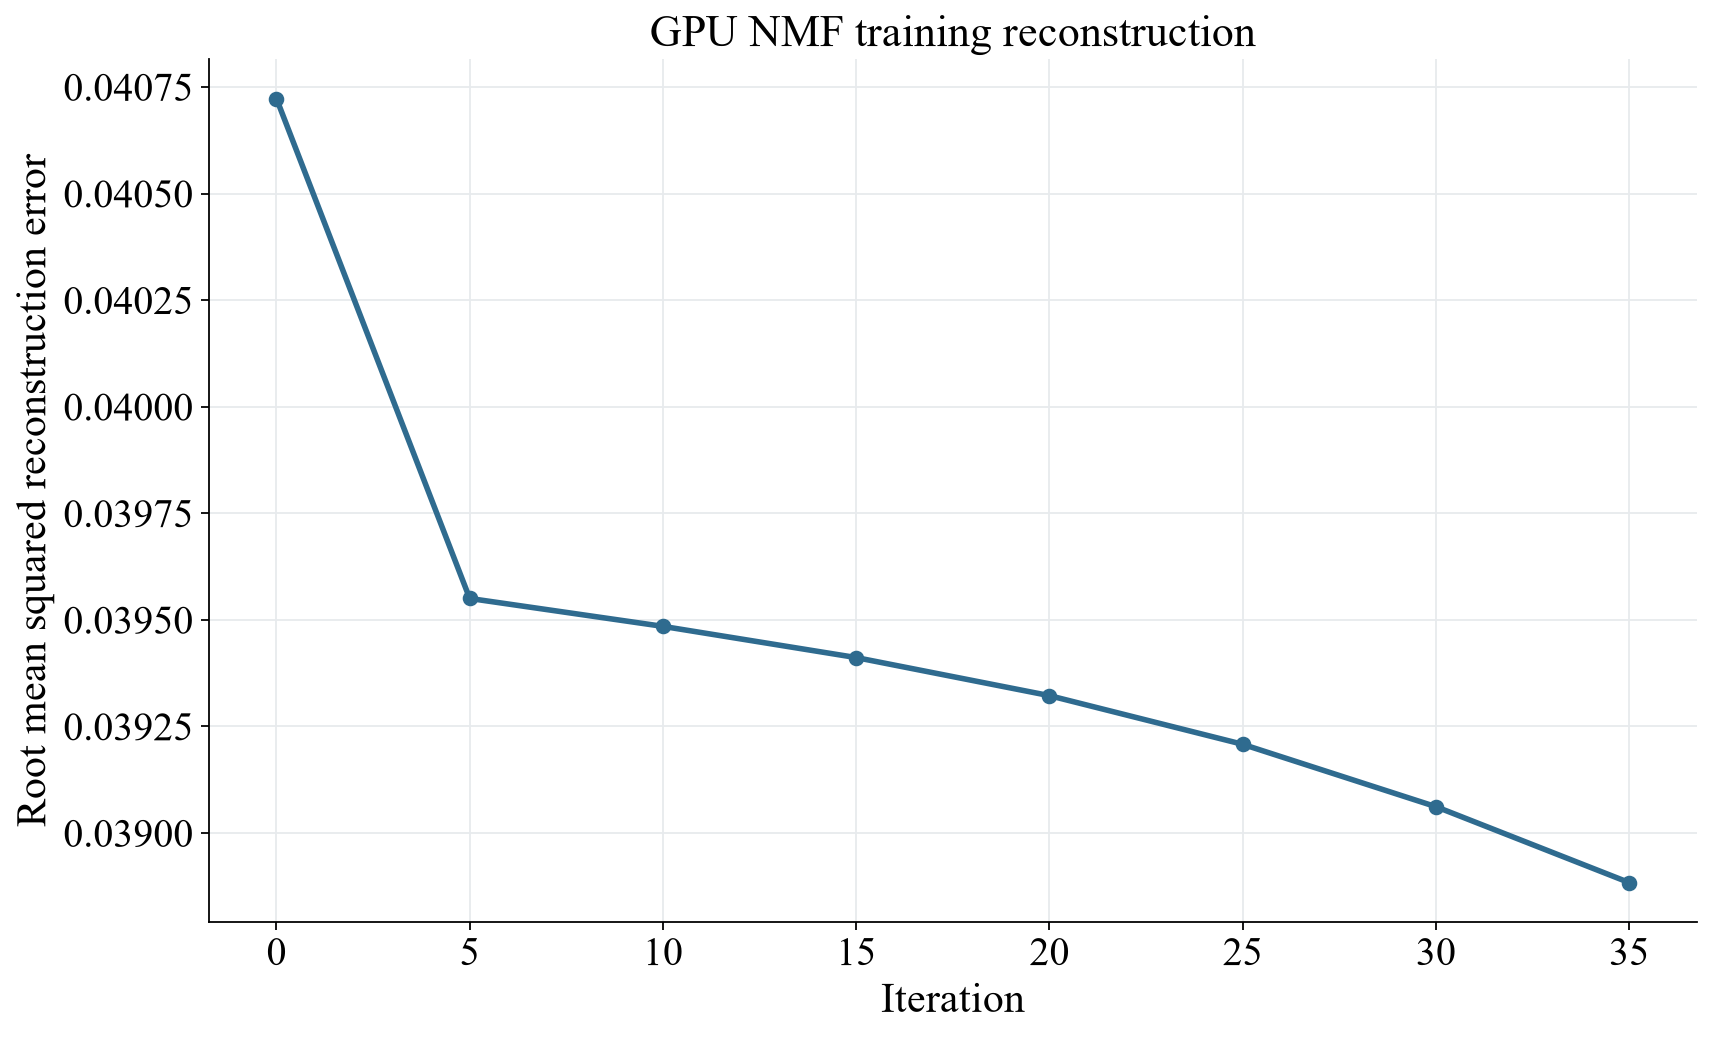

In [12]:
V = torch.from_numpy(hashed[train_idx]).to(device)
torch.manual_seed(SEEDS[0])
topic_count = 48
W = torch.rand(len(train_idx), topic_count, device=device) + 0.05
H = torch.rand(topic_count, hashed.shape[1], device=device) + 0.05
curve = []
start = time.perf_counter()
for iteration in range(40):
    W *= ((V @ H.T) / (W @ (H @ H.T) + 1e-6)).clamp(0.05, 20)
    H *= ((W.T @ V) / ((W.T @ W) @ H + 1e-6)).clamp(0.05, 20)
    if iteration % 5 == 0:
        curve.append(float(F.mse_loss(W @ H, V).sqrt()))
nmf_seconds = time.perf_counter() - start


def infer_nmf(values, basis, steps=30):
    matrix = torch.from_numpy(values).to(device)
    weights = torch.ones(len(values), basis.shape[0], device=device)
    gram = basis @ basis.T
    for _ in range(steps):
        weights *= ((matrix @ basis.T) / (weights @ gram + 1e-6)).clamp(0.05, 20)
    return weights.detach()


nmf_features = np.zeros((len(modeling), topic_count), np.float32)
nmf_features[train_idx] = W.detach().cpu()
for indices in role_indices.values():
    nmf_features[indices] = infer_nmf(hashed[indices], H).cpu()
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(np.arange(len(curve)) * 5, curve, color=PALETTE['blue'], linewidth=2.5, marker='o')
ax.set_title('GPU NMF training reconstruction')
ax.set_xlabel('Iteration')
ax.set_ylabel('Root mean squared reconstruction error')
ax.grid(color=PALETTE['light_gray'])
plt.show()
del V, W
torch.cuda.empty_cache()

## GPU Dirichlet topic-mixture representation

This probabilistic, simplex-constrained implementation is reported as LDA-style, not as collapsed-Gibbs LDA.


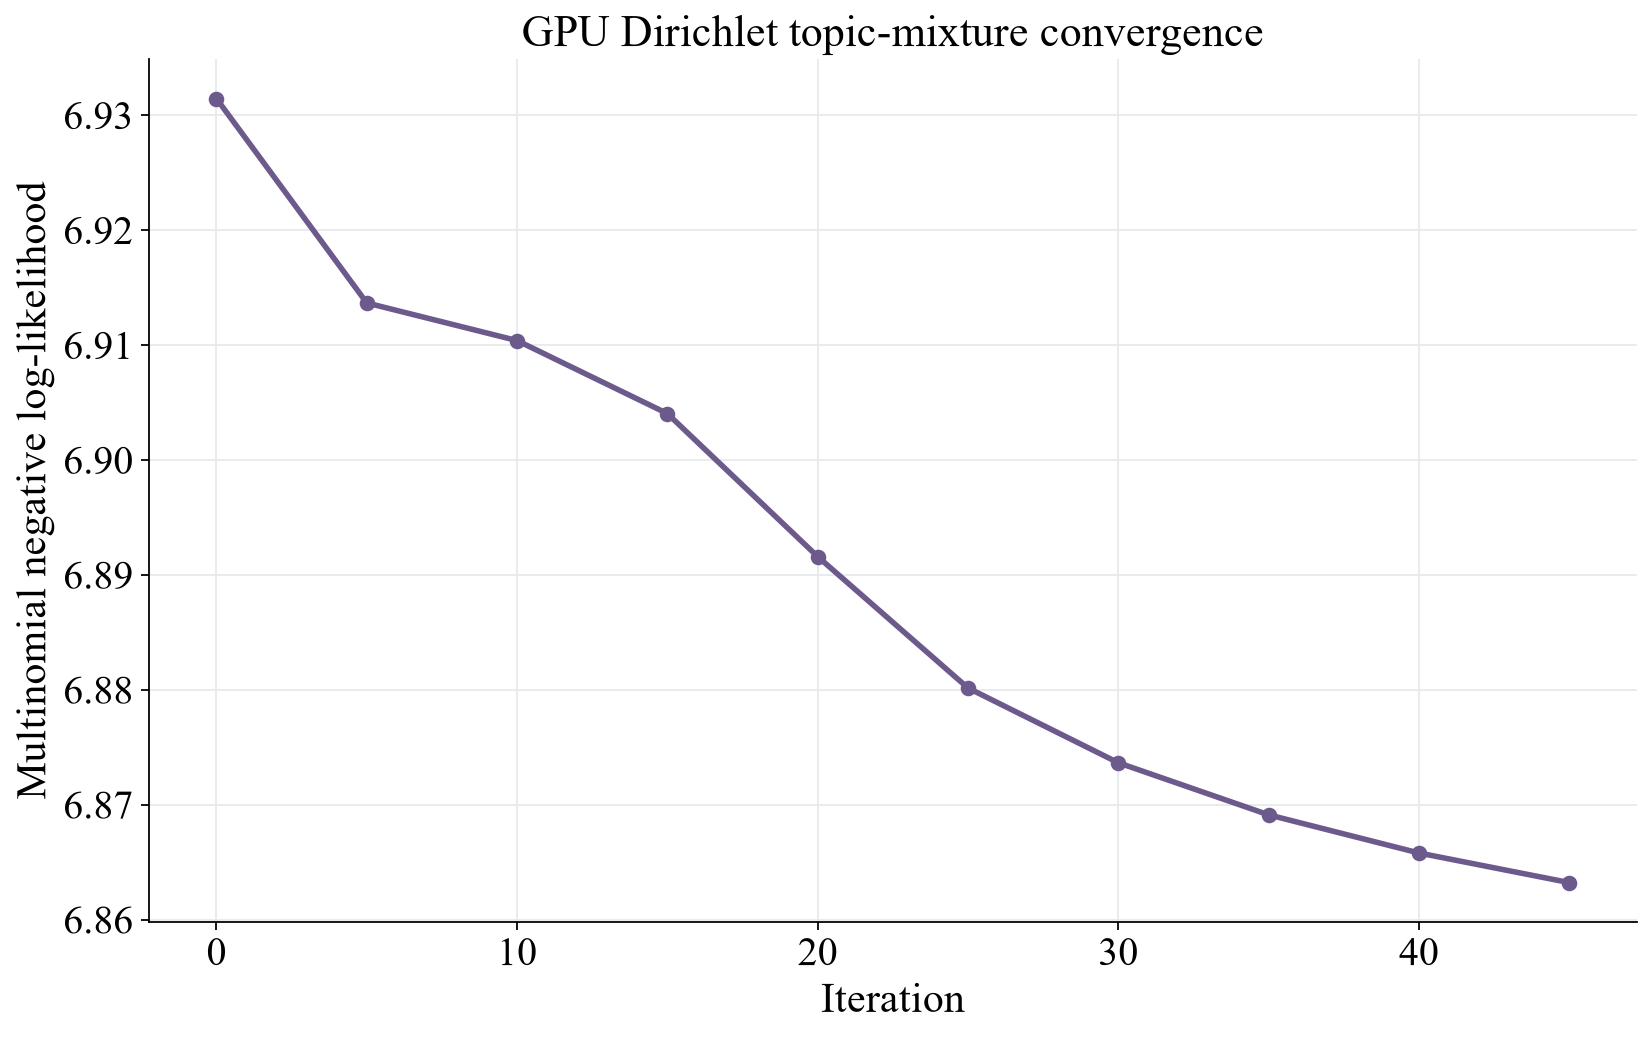

In [13]:
torch.manual_seed(SEEDS[1])
K = 40
V = torch.from_numpy(hashed[train_idx]).to(device)
V = V / (V.sum(1, keepdim=True) + 1e-7)
theta_logits = nn.Parameter(torch.randn(len(train_idx), K, device=device) * 0.03)
beta_logits = nn.Parameter(torch.randn(K, hashed.shape[1], device=device) * 0.03)
optimizer = torch.optim.Adam([theta_logits, beta_logits], lr=0.12)
curve = []
start = time.perf_counter()
for iteration in range(50):
    optimizer.zero_grad(set_to_none=True)
    theta = theta_logits.softmax(1)
    beta = beta_logits.softmax(1)
    nll = -(V * torch.log(theta @ beta + 1e-8)).sum(1).mean()
    loss = nll + 0.002 * (theta * torch.log(theta + 1e-8)).sum(1).mean()
    loss.backward()
    optimizer.step()
    if iteration % 5 == 0:
        curve.append(float(nll))
lda_seconds = time.perf_counter() - start
beta = beta_logits.softmax(1).detach()


def infer_topics(values, basis, steps=35):
    matrix = torch.from_numpy(values).to(device)
    matrix = matrix / (matrix.sum(1, keepdim=True) + 1e-7)
    logits = nn.Parameter(torch.zeros(len(values), basis.shape[0], device=device))
    opt = torch.optim.Adam([logits], lr=0.18)
    for _ in range(steps):
        opt.zero_grad(set_to_none=True)
        mix = logits.softmax(1)
        loss = (
            -(matrix * torch.log(mix @ basis + 1e-8)).sum(1).mean()
            + 0.002 * (mix * torch.log(mix + 1e-8)).sum(1).mean()
        )
        loss.backward()
        opt.step()
    return logits.softmax(1).detach()


lda_features = np.zeros((len(modeling), K), np.float32)
lda_features[train_idx] = theta_logits.softmax(1).detach().cpu()
for indices in role_indices.values():
    lda_features[indices] = infer_topics(hashed[indices], beta).cpu()
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(np.arange(len(curve)) * 5, curve, color=PALETTE['purple'], linewidth=2.5, marker='o')
ax.set_title('GPU Dirichlet topic-mixture convergence')
ax.set_xlabel('Iteration')
ax.set_ylabel('Multinomial negative log-likelihood')
ax.grid(color=PALETTE['light_gray'])
plt.show()
del V, theta_logits, beta_logits
torch.cuda.empty_cache()

## Shared dense GPU head


In [14]:
class DenseHead(nn.Module):
    def __init__(self, input_dim, hidden=0):
        super().__init__()
        self.network = (
            nn.Linear(input_dim, N_CLASSES)
            if hidden == 0
            else nn.Sequential(
                nn.LayerNorm(input_dim),
                nn.Linear(input_dim, hidden),
                nn.GELU(),
                nn.Dropout(0.15),
                nn.Linear(hidden, N_CLASSES),
            )
        )

    def forward(self, x):
        return self.network(x)


def fit_dense(features, seed, hidden=0, epochs=120, lr=0.01, weight_decay=1e-3):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    train_tensor = torch.from_numpy(features[train_idx].astype(np.float32)).to(device)
    selection_tensor = torch.from_numpy(features[selection_idx].astype(np.float32)).to(device)
    model = DenseHead(features.shape[1], hidden).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_state = None
    best = -1
    stale = 0
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(train_tensor), y_train_gpu, weight=class_weight)
        loss.backward()
        optimizer.step()
        if epoch % 3 == 0:
            with torch.no_grad():
                pred = model(selection_tensor).argmax(1).cpu().numpy()
            score = f1_score(y[selection_idx], pred, average='macro')
            if score > best + 1e-4:
                best = score
                best_state = deepcopy(model.state_dict())
                stale = 0
            else:
                stale += 1
            if stale >= 8:
                break
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    model.eval()
    outputs = {}
    with torch.no_grad():
        for role, indices in role_indices.items():
            values = torch.from_numpy(features[indices].astype(np.float32)).to(device)
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            logits = model(values)
            torch.cuda.synchronize()
            outputs[role] = logits.float().cpu().numpy()
            if role == 'validation_selection':
                latency = (time.perf_counter() - t0) * 1000 / len(indices)
    return model, outputs, seconds, latency, best

In [15]:
topic_rows = []
for name, features, pre_seconds in [
    ('NMF topics + GPU Logistic', nmf_features, nmf_seconds),
    ('LDA-style Dirichlet topics + GPU Logistic', lda_features, lda_seconds),
]:
    for seed in SEEDS:
        model, outputs, seconds, latency, best = fit_dense(features, seed, epochs=140, lr=0.025)
        for role, indices in role_indices.items():
            register(
                name,
                'baseline',
                'primary_text',
                seed,
                role,
                indices,
                outputs[role],
                seconds + pre_seconds,
                latency,
                sum(p.numel() for p in model.parameters()),
            )
        torch.save(
            {'state_dict': model.state_dict(), 'input_dim': features.shape[1]},
            ARTIFACTS / f'{re.sub("[^a-z0-9]+","_",name.lower()).strip("_")}__seed_{seed}.pt',
        )
        topic_rows.append((name, seed, best))
        del model
        torch.cuda.empty_cache()
display(pd.DataFrame(topic_rows, columns=['model', 'seed', 'selection_macro_f1']))

,model,seed,selection_macro_f1
0,NMF topics + GPU Logistic,20260417,0.437787
1,NMF topics + GPU Logistic,20260519,0.443822
2,NMF topics + GPU Logistic,20260623,0.436005
3,LDA-style Dirichlet topics + GPU Logistic,20260417,0.506758
4,LDA-style Dirichlet topics + GPU Logistic,20260519,0.485222
5,LDA-style Dirichlet topics + GPU Logistic,20260623,0.503804


## Matched linear heads for frozen transformer embeddings

Identical heads isolate representation quality.


In [16]:
embedding_rows = []
for name, features in embeddings.items():
    normalized_features = (
        features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-8)
    ).astype(np.float32)
    family = 'legacy_anchor' if name.startswith('Legacy') else 'sota'
    for seed in SEEDS:
        model, outputs, seconds, latency, best = fit_dense(
            normalized_features, seed, epochs=150, lr=0.02
        )
        for role, indices in role_indices.items():
            register(
                name,
                family,
                'primary_text',
                seed,
                role,
                indices,
                outputs[role],
                seconds,
                latency,
                sum(p.numel() for p in model.parameters()),
            )
        torch.save(
            {'state_dict': model.state_dict(), 'input_dim': normalized_features.shape[1]},
            ARTIFACTS / f'{re.sub("[^a-z0-9]+","_",name.lower()).strip("_")}__seed_{seed}.pt',
        )
        embedding_rows.append((name, seed, best, seconds))
        del model
        torch.cuda.empty_cache()
display(
    pd.DataFrame(
        embedding_rows, columns=['model', 'seed', 'selection_macro_f1', 'training_seconds']
    )
)

,model,seed,selection_macro_f1,training_seconds
0,Legacy SPECTER + GPU linear,20260417,0.694175,0.224352
1,Legacy SPECTER + GPU linear,20260519,0.692909,0.164452
2,Legacy SPECTER + GPU linear,20260623,0.694556,0.177305
3,SPECTER2-base + GPU linear,20260417,0.695584,0.231829
4,SPECTER2-base + GPU linear,20260519,0.696834,0.241015
5,SPECTER2-base + GPU linear,20260623,0.696829,0.226424
6,Jina v5 nano + GPU linear,20260417,0.623274,0.221214
7,Jina v5 nano + GPU linear,20260519,0.621967,0.218638
8,Jina v5 nano + GPU linear,20260623,0.621316,0.230908
9,Qwen3-Embedding-0.6B instructed + GPU linear,20260417,0.719312,0.085696


## Nonlinear Jina v5 comparator


In [17]:
jina = embeddings['Jina v5 nano + GPU linear']
jina = (jina / (np.linalg.norm(jina, axis=1, keepdims=True) + 1e-8)).astype(np.float32)
rows = []
for seed in SEEDS:
    model, outputs, seconds, latency, best = fit_dense(
        jina, seed, hidden=128, epochs=70, lr=0.004, weight_decay=0.002
    )
    for role, indices in role_indices.items():
        register(
            'Jina v5 nano + GPU MLP',
            'sota',
            'primary_text',
            seed,
            role,
            indices,
            outputs[role],
            seconds,
            latency,
            sum(p.numel() for p in model.parameters()),
        )
    torch.save(
        {'state_dict': model.state_dict(), 'input_dim': jina.shape[1], 'hidden': 128},
        ARTIFACTS / f'jina_v5_nano_gpu_mlp__seed_{seed}.pt',
    )
    rows.append((seed, best, seconds))
    del model
    torch.cuda.empty_cache()
display(pd.DataFrame(rows, columns=['seed', 'selection_macro_f1', 'training_seconds']))

,seed,selection_macro_f1,training_seconds
0,20260417,0.623308,0.143637
1,20260519,0.644871,0.119585
2,20260623,0.634199,0.128914


## Matched four-modal representation

The same proxy-safe lexical, Jina semantic, stable metadata, and title+abstract concept inputs will be available to MASSK. Reference keywords are not predictor inputs.


In [18]:
concept_hash = hash_nonnegative(concept, 256).toarray().astype(np.float32)
cmean = concept_hash[train_idx].mean(0, keepdims=True)
cstd = np.maximum(concept_hash[train_idx].std(0, keepdims=True), 1e-4)
concept_modal = ((concept_hash - cmean) / cstd).astype(np.float32)
mmean = metadata_enriched[train_idx].mean(0, keepdims=True)
mstd = np.maximum(metadata_enriched[train_idx].std(0, keepdims=True), 1e-4)
metadata_modal = ((metadata_enriched - mmean) / mstd).astype(np.float32)
all_modal = np.concatenate([hashed_standard, jina, metadata_modal, concept_modal], axis=1).astype(
    np.float32
)
starts = np.cumsum(
    [0, hashed_standard.shape[1], jina.shape[1], metadata_modal.shape[1], concept_modal.shape[1]]
)
modal_slices = {
    name: [int(starts[i]), int(starts[i + 1])]
    for i, name in enumerate(['lexical', 'semantic', 'metadata', 'concept'])
}
display(
    pd.DataFrame(
        [{'branch': name, 'dimensions': end - start} for name, (start, end) in modal_slices.items()]
    )
)

,branch,dimensions
0,lexical,1024
1,semantic,768
2,metadata,14
3,concept,256


## Strong four-modal concat MLP


In [19]:
rows = []
for seed in SEEDS:
    model, outputs, seconds, latency, best = fit_dense(
        all_modal, seed, hidden=128, epochs=70, lr=0.003, weight_decay=0.003
    )
    for role, indices in role_indices.items():
        register(
            'Four-modal concat GPU MLP',
            'matched_multimodal',
            'matched_four_modal',
            seed,
            role,
            indices,
            outputs[role],
            seconds,
            latency,
            sum(p.numel() for p in model.parameters()),
        )
    torch.save(
        {
            'state_dict': model.state_dict(),
            'input_dim': all_modal.shape[1],
            'hidden': 128,
            'modal_slices': modal_slices,
        },
        ARTIFACTS / f'four_modal_concat_gpu_mlp__seed_{seed}.pt',
    )
    rows.append((seed, best, seconds))
    del model
    torch.cuda.empty_cache()
display(pd.DataFrame(rows, columns=['seed', 'selection_macro_f1', 'training_seconds']))

,seed,selection_macro_f1,training_seconds
0,20260417,0.468232,0.078125
1,20260519,0.464362,0.075233
2,20260623,0.471480,0.110696


## Strong four-modal CUDA XGBoost


In [20]:
rows = []
for seed in SEEDS:
    model = xgb.XGBClassifier(
        n_estimators=320,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.82,
        colsample_bytree=0.72,
        min_child_weight=2,
        reg_lambda=2,
        objective='multi:softprob',
        num_class=N_CLASSES,
        eval_metric='mlogloss',
        random_state=seed,
        tree_method='hist',
        device='cuda',
        n_jobs=1,
    )
    start = time.perf_counter()
    model.fit(
        all_modal[train_idx],
        y[train_idx],
        eval_set=[(all_modal[selection_idx], y[selection_idx])],
        verbose=False,
    )
    seconds = time.perf_counter() - start
    for role, indices in role_indices.items():
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        probabilities = model.predict_proba(all_modal[indices])
        torch.cuda.synchronize()
        latency = (time.perf_counter() - t0) * 1000 / len(indices)
        register(
            'Four-modal GPU XGBoost',
            'matched_multimodal',
            'matched_four_modal',
            seed,
            role,
            indices,
            np.log(np.clip(probabilities, 1e-7, 1)),
            seconds,
            latency,
            0,
        )
    model.save_model(ARTIFACTS / f'four_modal_gpu_xgboost__seed_{seed}.json')
    rows.append(
        (
            seed,
            classification_metrics(
                y[selection_idx],
                np.log(np.clip(model.predict_proba(all_modal[selection_idx]), 1e-7, 1)),
            )[0]['macro_f1'],
            seconds,
        )
    )
display(pd.DataFrame(rows, columns=['seed', 'selection_macro_f1', 'training_seconds']))

,seed,selection_macro_f1,training_seconds
0,20260417,0.610131,50.208769
1,20260519,0.614987,49.759102
2,20260623,0.610635,50.336537


## Static lexical–Jina late fusion

Its weight is selected on validation-selection only.


In [21]:
rows = []
for seed in SEEDS:
    lexical_logits = model_logits['TF–IDF + GPU Logistic'][seed]
    semantic_logits = model_logits['Jina v5 nano + GPU linear'][seed]
    candidates = []
    for alpha in np.linspace(0, 1, 21):
        candidates.append(
            (
                classification_metrics(
                    y[selection_idx],
                    alpha * lexical_logits['validation_selection']
                    + (1 - alpha) * semantic_logits['validation_selection'],
                )[0]['macro_f1'],
                float(alpha),
            )
        )
    best, alpha = max(candidates)
    for role, indices in role_indices.items():
        register(
            'Static lexical–Jina late fusion',
            'matched_multimodal',
            'matched_four_modal',
            seed,
            role,
            indices,
            alpha * lexical_logits[role] + (1 - alpha) * semantic_logits[role],
            0,
            0.01,
            0,
        )
    rows.append((seed, alpha, best))
display(pd.DataFrame(rows, columns=['seed', 'lexical_weight', 'selection_macro_f1']))

,seed,lexical_weight,selection_macro_f1
0,20260417,0.65,0.674612
1,20260519,0.35,0.673086
2,20260623,0.65,0.674236


## ModernBERT-base rank-8 LoRA

Three seeds use identical title+abstract tokenization and three epochs. This supplies a genuine compact fine-tuned current transformer comparator.


In [22]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import LoraConfig, TaskType, get_peft_model

MODERNBERT_ID = 'answerdotai/ModernBERT-base'
MODERNBERT_REVISION = '8949b909ec900327062f0ebf497f51aef5e6f0c8'
tokenizer = AutoTokenizer.from_pretrained(
    MODERNBERT_ID, revision=MODERNBERT_REVISION, cache_dir='/home/azyqan/cache/huggingface'
)
active_idx = np.concatenate([train_idx, validation_idx])
encoded = tokenizer(
    modeling.iloc[active_idx].paper_text.tolist(),
    padding='max_length',
    truncation=True,
    max_length=512,
    return_tensors='pt',
)
position = {int(g): i for i, g in enumerate(active_idx)}


def make_loader(indices, batch, shuffle=False, seed=0):
    local = np.array([position[int(i)] for i in indices])
    dataset = TensorDataset(
        encoded['input_ids'][local], encoded['attention_mask'][local], torch.from_numpy(y[indices])
    )
    return DataLoader(
        dataset,
        batch_size=batch,
        shuffle=shuffle,
        generator=torch.Generator().manual_seed(seed),
        pin_memory=True,
    )


def predict_bert(model, indices, batch=32):
    output = []
    model.eval()
    start = time.perf_counter()
    with torch.no_grad():
        for ids, mask, _ in make_loader(indices, batch):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                logits = model(
                    input_ids=ids.to(device, non_blocking=True),
                    attention_mask=mask.to(device, non_blocking=True),
                ).logits
            output.append(logits.float().cpu())
    torch.cuda.synchronize()
    return torch.cat(output).numpy(), (time.perf_counter() - start) * 1000 / len(indices)


rows = []
for seed in SEEDS:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    base = AutoModelForSequenceClassification.from_pretrained(
        MODERNBERT_ID,
        revision=MODERNBERT_REVISION,
        num_labels=N_CLASSES,
        cache_dir='/home/azyqan/cache/huggingface',
        dtype=torch.bfloat16,
        attn_implementation='sdpa',
    )
    config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8,
        lora_alpha=16,
        lora_dropout=0.08,
        target_modules=['Wqkv', 'Wo'],
        modules_to_save=['classifier'],
    )
    model = get_peft_model(base, config).to(device)
    model.gradient_checkpointing_enable()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=2e-4, weight_decay=0.01
    )
    best_state = None
    best = -1
    start = time.perf_counter()
    for epoch in range(8):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loader = make_loader(train_idx, 4, True, seed + epoch)
        for step, (ids, mask, labels) in enumerate(loader):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                logits = model(
                    input_ids=ids.to(device, non_blocking=True),
                    attention_mask=mask.to(device, non_blocking=True),
                ).logits
                loss = (
                    F.cross_entropy(
                        logits,
                        labels.to(device, non_blocking=True),
                        weight=class_weight,
                        label_smoothing=0.02,
                    )
                    / 8
                )
            loss.backward()
            if (step + 1) % 8 == 0 or step + 1 == len(loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
        selection_logits, _ = predict_bert(model, selection_idx)
        score = f1_score(y[selection_idx], selection_logits.argmax(1), average='macro')
        if score > best:
            best = score
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
                if 'lora_' in name or 'classifier' in name
            }
    current = model.state_dict()
    current.update(best_state)
    model.load_state_dict(current, strict=False)
    seconds = time.perf_counter() - start
    for role, indices in role_indices.items():
        logits, latency = predict_bert(model, indices)
        register(
            'ModernBERT-base LoRA',
            'sota',
            'primary_text',
            seed,
            role,
            indices,
            logits,
            seconds,
            latency,
            trainable,
        )
    torch.save(
        {
            'trainable_state_dict': best_state,
            'model_id': MODERNBERT_ID,
            'revision': MODERNBERT_REVISION,
            'lora_rank': 8,
            'max_length': 512,
            'effective_batch_size': 32,
            'class_weighted': True,
            'num_labels': N_CLASSES,
        },
        ARTIFACTS / f'modernbert_base_lora__seed_{seed}.pt',
    )
    rows.append((seed, best, seconds, trainable))
    del model, base, current, best_state
    gc.collect()
    torch.cuda.empty_cache()
display(
    pd.DataFrame(
        rows, columns=['seed', 'selection_macro_f1', 'training_seconds', 'trainable_parameters']
    )
)

,seed,selection_macro_f1,training_seconds,trainable_parameters
0,20260417,0.714804,1405.697779,1155080
1,20260519,0.709355,1419.213906,1155080
2,20260623,0.715526,1377.647320,1155080


## Selection-only comparison

Mean ± sample SD across fixed seeds; no confirmatory result is present.


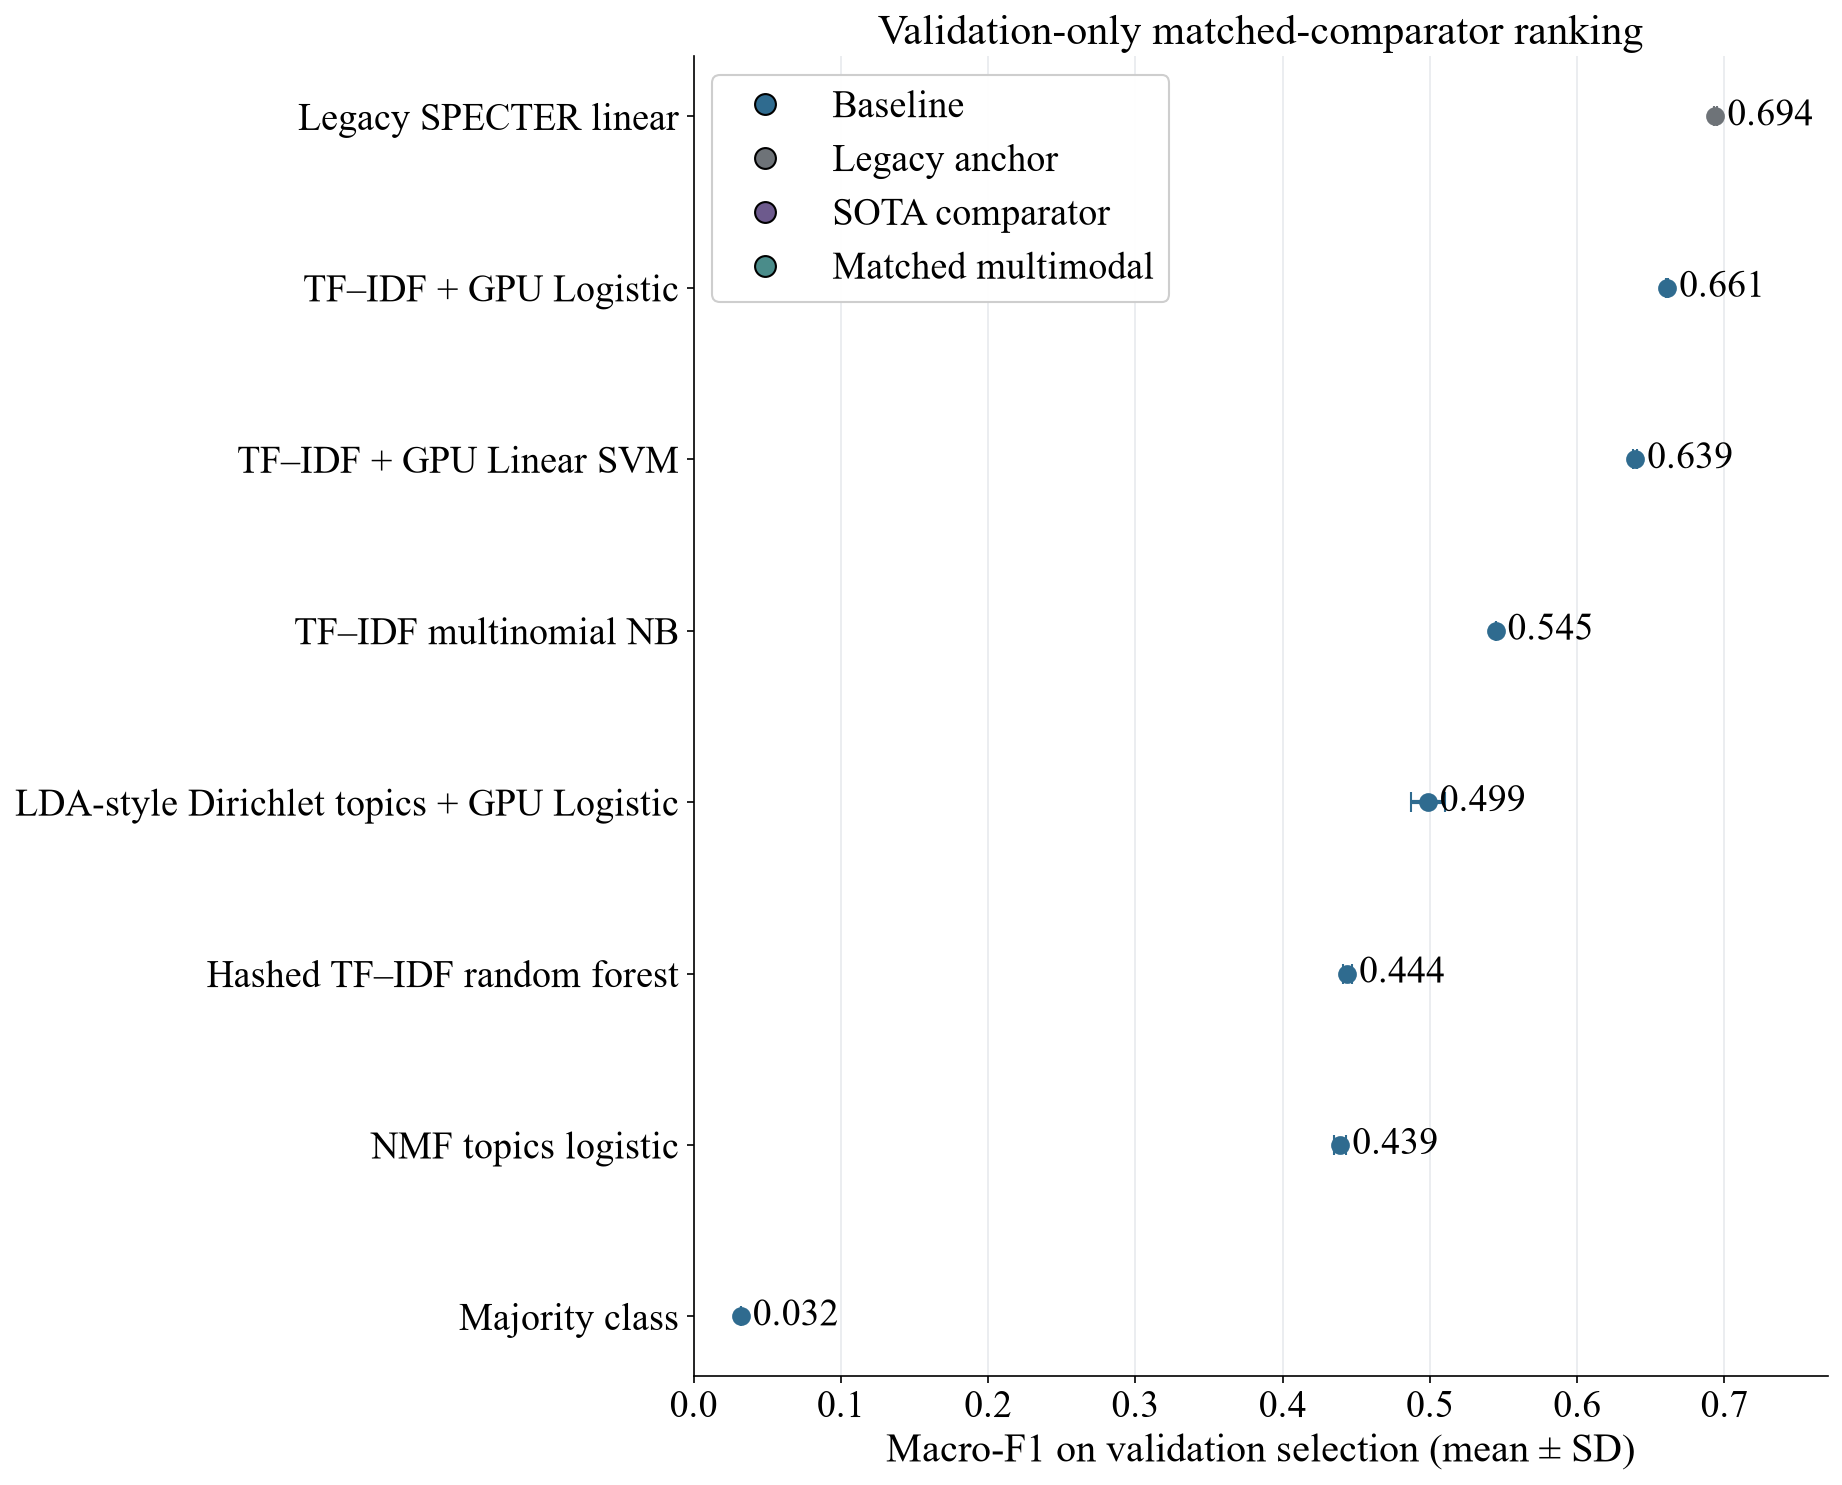

,model,family,track,macro_f1_mean,seed_count,balanced_accuracy_mean,ece_mean,macro_f1_sd
10,Qwen3-Embedding-0.6B instructed + GPU linear,sota,primary_text,0.719295,3,0.724839,0.042518,0.000576
8,ModernBERT-base LoRA,sota,primary_text,0.713229,3,0.718995,0.076629,0.003374
11,SPECTER2 classification adapter + GPU linear,sota,primary_text,0.709918,3,0.715209,0.042973,0.000611
13,SciNCL + GPU linear,sota,primary_text,0.701871,3,0.709005,0.052362,0.001057
12,SPECTER2-base + GPU linear,sota,primary_text,0.696415,3,0.704163,0.032820,0.000720
6,Legacy SPECTER + GPU linear,legacy_anchor,primary_text,0.693880,3,0.701629,0.027024,0.000862
14,Static lexical–Jina late fusion,matched_multimodal,matched_four_modal,0.673978,3,0.679854,0.062196,0.000795
16,TF–IDF + GPU Logistic,baseline,primary_text,0.661174,3,0.667736,0.133817,0.000559
3,Jina v5 nano + GPU MLP,sota,primary_text,0.642857,3,0.646022,0.065773,0.007199
15,TF–IDF + GPU Linear SVM,baseline,primary_text,0.639442,3,0.639238,0.066638,0.001279


In [23]:
metrics_df = pd.DataFrame(metric_rows)
summary = (
    metrics_df[metrics_df.partition.eq('validation_selection')]
    .groupby(['model', 'family', 'track'], as_index=False)
    .agg(
        macro_f1_mean=('macro_f1', 'mean'),
        macro_f1_std=('macro_f1', 'std'),
        seed_count=('seed', 'nunique'),
        balanced_accuracy_mean=('balanced_accuracy', 'mean'),
        ece_mean=('ece_15', 'mean'),
    )
    .sort_values('macro_f1_mean')
)
short_model_labels = {
    'Qwen3-Embedding-0.6B instructed + GPU linear': 'Qwen3 embedding linear',
    'SPECTER2 classification adapter + GPU linear': 'SPECTER2 adapter linear',
    'SPECTER2-base + GPU linear': 'SPECTER2-base linear',
    'Legacy SPECTER + GPU linear': 'Legacy SPECTER linear',
    'Static lexical–Jina late fusion': 'Lexical–Jina fusion',
    'TF–IDF + GPU Multinomial NB': 'TF–IDF multinomial NB',
    'Four-modal concat GPU MLP': 'Four-modal MLP',
    'Hashed TF–IDF + GPU Random Forest': 'Hashed TF–IDF random forest',
    'NMF topics + GPU Logistic': 'NMF topics logistic',
}
summary['display_model'] = summary['model'].map(short_model_labels).fillna(summary['model'])
family_colors = {
    'baseline': PALETTE['blue'],
    'legacy_anchor': PALETTE['gray'],
    'sota': PALETTE['purple'],
    'matched_multimodal': PALETTE['teal'],
}
positions = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(12, 11))
for position, row in enumerate(summary.itertuples(index=False)):
    error = 0 if pd.isna(row.macro_f1_std) else row.macro_f1_std
    ax.errorbar(
        row.macro_f1_mean,
        position,
        xerr=error,
        fmt='o',
        markersize=8,
        color=family_colors[row.family],
        ecolor=family_colors[row.family],
        elinewidth=2,
        capsize=5,
    )
    ax.text(
        row.macro_f1_mean + 0.008, position, f'{row.macro_f1_mean:.3f}', va='center', fontsize=18
    )
ax.set_yticks(positions, summary['display_model'])
ax.set_xlim(0, 0.77)
ax.set_title('Validation-only matched-comparator ranking')
ax.set_xlabel('Macro-F1 on validation selection (mean ± SD)')
ax.set_ylabel('')
ax.grid(axis='x', color=PALETTE['light_gray'])
handles = [
    plt.Line2D(
        [0], [0], marker='o', color='none', markerfacecolor=color, markersize=10, label=label
    )
    for label, color in [
        ('Baseline', PALETTE['blue']),
        ('Legacy anchor', PALETTE['gray']),
        ('SOTA comparator', PALETTE['purple']),
        ('Matched multimodal', PALETTE['teal']),
    ]
]
ax.legend(handles=handles, loc='upper left', frameon=True, facecolor='white', framealpha=0.96)
fig.subplots_adjust(left=0.34, right=0.97, bottom=0.11, top=0.91)
plt.show()
summary_display = summary.tail(12).sort_values('macro_f1_mean', ascending=False).copy()
summary_display['macro_f1_sd'] = summary_display.apply(
    lambda row: 'N/A — one seed' if row.seed_count < 2 else f'{row.macro_f1_std:.6f}', axis=1
)
display(summary_display.drop(columns='macro_f1_std'))

## Held-out temperature calibration


In [24]:
best_model = summary.iloc[-1].model
seed_table = metrics_df[
    (metrics_df.model.eq(best_model)) & metrics_df.partition.eq('validation_selection')
].sort_values('macro_f1', ascending=False)
best_seed = int(seed_table.iloc[0].seed)
fit_logits = torch.from_numpy(model_logits[best_model][best_seed]['validation_calibration_fit']).to(
    device
)
fit_labels = torch.from_numpy(y[calibration_fit_idx]).to(device)
log_temperature = nn.Parameter(torch.zeros((), device=device))
optimizer = torch.optim.LBFGS(
    [log_temperature], lr=0.05, max_iter=80, line_search_fn='strong_wolfe'
)


def closure():
    optimizer.zero_grad()
    loss = F.cross_entropy(fit_logits / torch.exp(log_temperature), fit_labels)
    loss.backward()
    return loss


optimizer.step(closure)
temperature = float(torch.exp(log_temperature).detach().cpu())
eval_logits = model_logits[best_model][best_seed]['validation_calibration_eval']
raw = classification_metrics(y[calibration_eval_idx], eval_logits)[0]
calibrated = classification_metrics(y[calibration_eval_idx], eval_logits / temperature)[0]
calibration_df = pd.DataFrame(
    [
        {
            'model': best_model,
            'seed': best_seed,
            'method': 'uncalibrated',
            'temperature': 1.0,
            **raw,
        },
        {
            'model': best_model,
            'seed': best_seed,
            'method': 'temperature_scaling',
            'temperature': temperature,
            **calibrated,
        },
    ]
)
display(
    calibration_df[['model', 'method', 'temperature', 'macro_f1', 'ece_15', 'brier_multiclass']]
)

,model,method,temperature,macro_f1,ece_15,brier_multiclass
0,Qwen3-Embedding-0.6B instructed + GPU linear,uncalibrated,1.000000,0.73568,0.056089,0.373992
1,Qwen3-Embedding-0.6B instructed + GPU linear,temperature_scaling,0.770725,0.73568,0.052344,0.373038


## Validation-only thematic-proxy retrieval

Validation-selection queries retrieve train papers. Relevance is same thematic class, so results do not imply citation-link relevance.


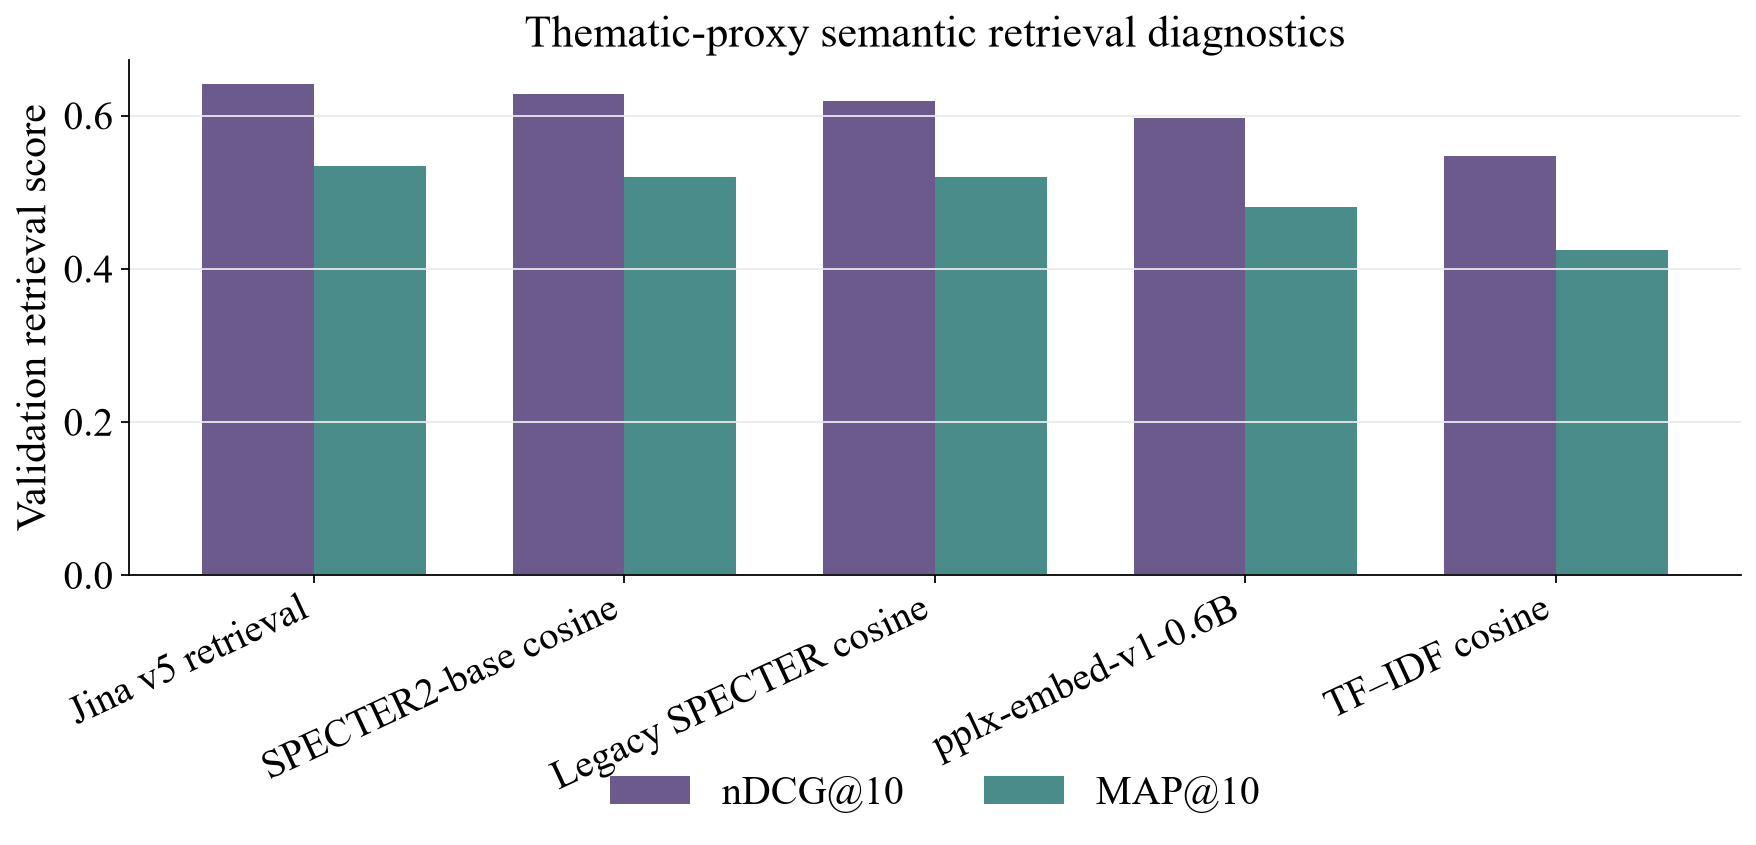

In [25]:
def ranking_metrics(neighbors, query_labels, document_labels, k=10):
    rows = []
    for found, label in zip(neighbors, query_labels):
        rel = (document_labels[found[:k]] == label).astype(float)
        total = max(1, int((document_labels == label).sum()))
        ranks = np.arange(1, k + 1)
        ideal = min(total, k)
        rows.append(
            (
                rel.mean(),
                rel.sum() / total,
                np.sum(np.cumsum(rel) / ranks * rel) / min(total, k),
                0 if not rel.any() else 1 / (np.flatnonzero(rel)[0] + 1),
                np.sum(rel / np.log2(ranks + 1))
                / np.sum(np.ones(ideal) / np.log2(np.arange(1, ideal + 1) + 1)),
                float(rel.any()),
            )
        )
    return np.mean(rows, axis=0)


def dense_topk(query, documents, k=10, batch=256):
    query = query / (np.linalg.norm(query, axis=1, keepdims=True) + 1e-8)
    documents = documents / (np.linalg.norm(documents, axis=1, keepdims=True) + 1e-8)
    docs = torch.from_numpy(documents.astype(np.float32)).to(device)
    result = []
    for start in range(0, len(query), batch):
        result.append(
            torch.topk(
                torch.from_numpy(query[start : start + batch].astype(np.float32)).to(device)
                @ docs.T,
                k=k,
                dim=1,
            )
            .indices.cpu()
            .numpy()
        )
    return np.vstack(result)


retrieval_rows = []
k = 10
vectorizer = joblib.load(PROJECT_ROOT / 'results/models/preprocessing_artifacts/word_tfidf.joblib')
word_dim = len(vectorizer.get_feature_names_out())
q = normalize(lexical[selection_idx, :word_dim])
d = normalize(lexical[train_idx, :word_dim])
neighbor_batches = []
for start in range(0, len(selection_idx), 200):
    scores = (q[start : start + 200] @ d.T).toarray()
    part = np.argpartition(scores, -k, axis=1)[:, -k:]
    order = np.argsort(np.take_along_axis(scores, part, axis=1), axis=1)[:, ::-1]
    neighbor_batches.append(np.take_along_axis(part, order, axis=1))
values = ranking_metrics(np.vstack(neighbor_batches), y[selection_idx], y[train_idx], k)
retrieval_rows.append(
    {
        'model': 'TF–IDF cosine',
        'family': 'baseline',
        'partition': 'validation_selection',
        **dict(
            zip(
                [
                    'precision_at_10',
                    'recall_at_10',
                    'map_at_10',
                    'mrr',
                    'ndcg_at_10',
                    'hit_rate_at_10',
                ],
                values,
            )
        ),
    }
)
specs = {
    'Legacy SPECTER cosine': (
        'semantic_embeddings_legacy_specter.npy',
        'semantic_embeddings_legacy_specter.npy',
        'legacy_anchor',
    ),
    'SPECTER2-base cosine': (
        'semantic_embeddings_specter2_base.npy',
        'semantic_embeddings_specter2_base.npy',
        'sota',
    ),
    'Jina v5 retrieval': (
        'retrieval_embeddings_jina_v5_queries.npy',
        'retrieval_embeddings_jina_v5_documents.npy',
        'sota',
    ),
    'pplx-embed-v1-0.6B': (
        'retrieval_embeddings_pplx_0_6b.npy',
        'retrieval_embeddings_pplx_0_6b.npy',
        'sota',
    ),
}
for name, (qfile, dfile, family) in specs.items():
    query_values = np.load(DATASET / 'unified' / qfile)[original_indices[selection_idx]]
    document_values = np.load(DATASET / 'unified' / dfile)[original_indices[train_idx]]
    neighbors = dense_topk(query_values, document_values, k)
    values = ranking_metrics(neighbors, y[selection_idx], y[train_idx], k)
    retrieval_rows.append(
        {
            'model': name,
            'family': family,
            'partition': 'validation_selection',
            **dict(
                zip(
                    [
                        'precision_at_10',
                        'recall_at_10',
                        'map_at_10',
                        'mrr',
                        'ndcg_at_10',
                        'hit_rate_at_10',
                    ],
                    values,
                )
            ),
        }
    )
retrieval_df = pd.DataFrame(retrieval_rows).sort_values('ndcg_at_10', ascending=False)
fig, ax = plt.subplots(figsize=(13, 7))
pos = np.arange(len(retrieval_df))
width = 0.36
ax.bar(pos - width / 2, retrieval_df.ndcg_at_10, width, label='nDCG@10', color=PALETTE['purple'])
ax.bar(pos + width / 2, retrieval_df.map_at_10, width, label='MAP@10', color=PALETTE['teal'])
ax.set_xticks(pos, retrieval_df.model, rotation=25, ha='right')
ax.set_ylabel('Validation retrieval score')
ax.set_title('Thematic-proxy semantic retrieval diagnostics')
ax.grid(axis='y', color=PALETTE['light_gray'])
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.42)
plt.show()

## Metadata-held-out key-concept baselines

Candidates come only from title+abstract. Exact canonical match is primary; relaxed token overlap is sensitivity analysis.


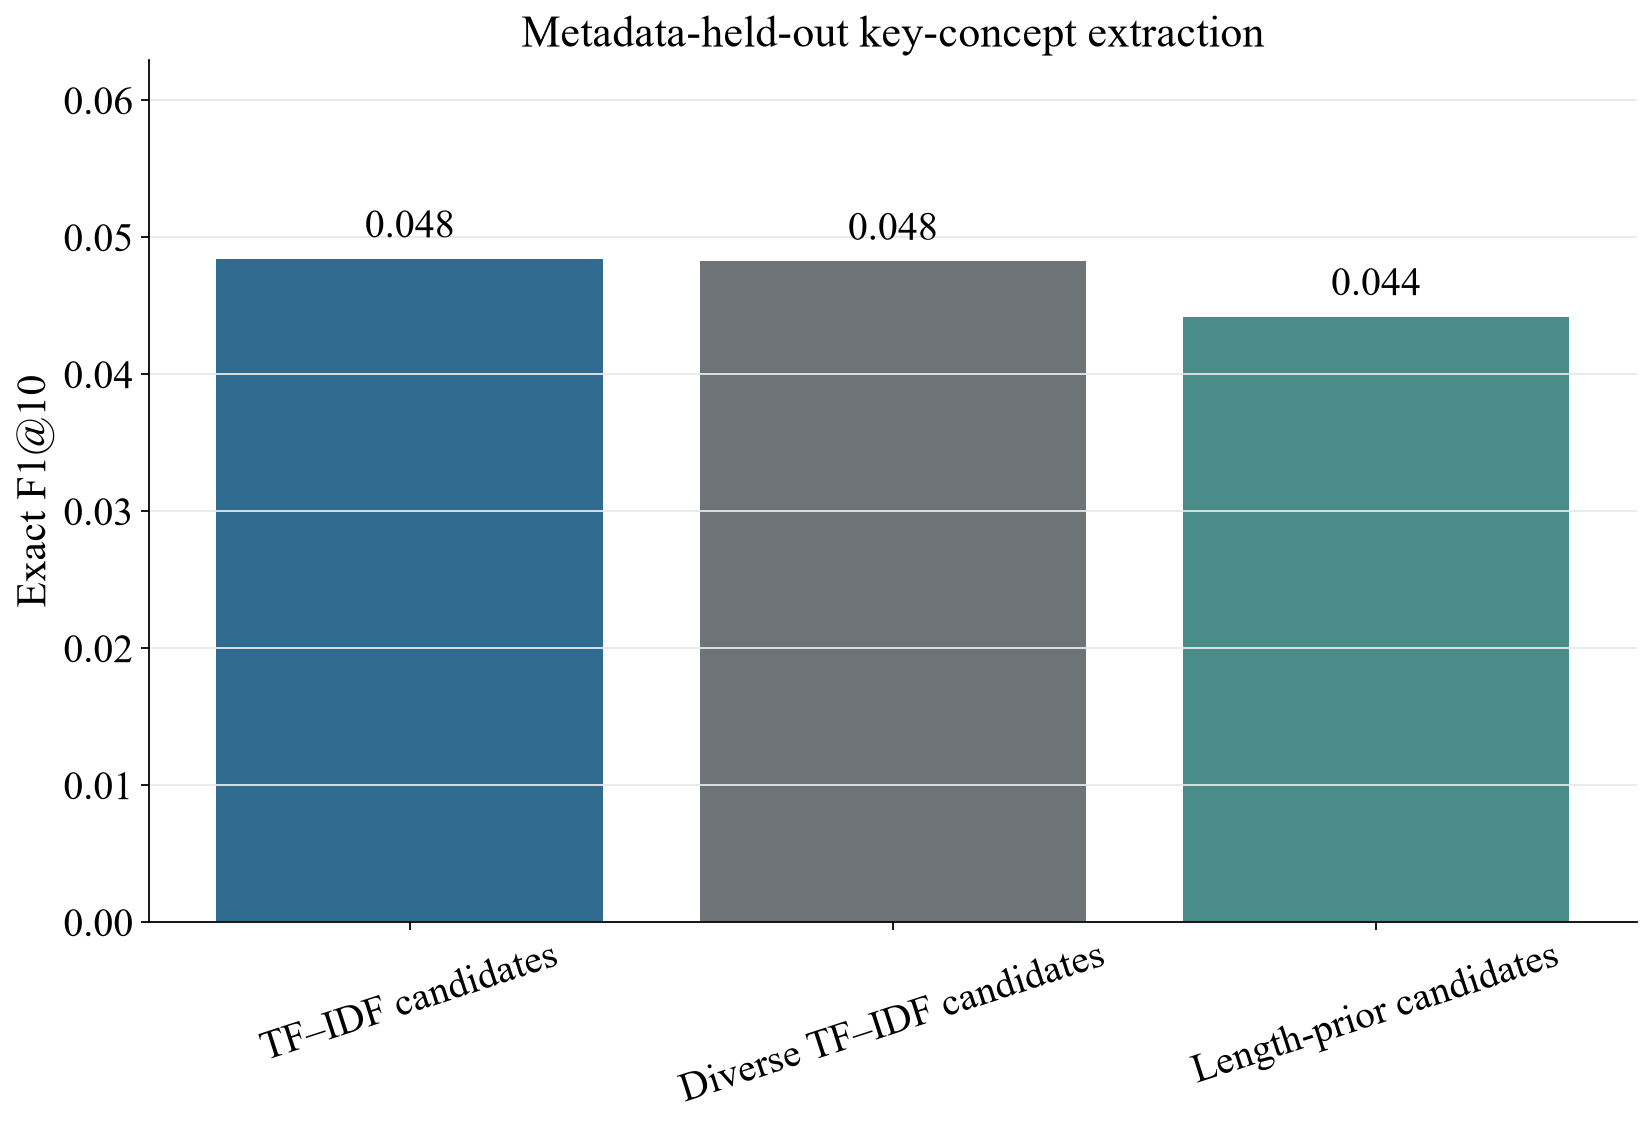

In [26]:
concept_frame = (
    pd.read_parquet(DATASET / 'unified/concept_features.parquet')
    .set_index('row_index')
    .loc[original_indices]
    .reset_index()
)


def parse_list(value):
    try:
        return json.loads(value) if isinstance(value, str) else list(value)
    except Exception:
        return []


def canonical(value):
    return re.sub(r'[^a-z0-9 ]+', ' ', str(value).lower()).strip()


def diverse(values, k=10):
    chosen = []
    for value in values:
        tokens = set(canonical(value).split())
        if tokens and all(
            len(tokens & set(canonical(other).split()))
            / max(1, len(tokens | set(canonical(other).split())))
            < 0.65
            for other in chosen
        ):
            chosen.append(value)
        if len(chosen) == k:
            break
    return chosen


def kp_score(predicted, reference, k=10):
    pred = [canonical(x) for x in predicted[:k] if canonical(x)]
    gold = {canonical(x) for x in reference if canonical(x)}
    exact = sum(x in gold for x in pred)
    relaxed = sum(
        any(
            len(set(x.split()) & set(g.split())) / max(1, len(set(x.split()) | set(g.split())))
            >= 0.75
            for g in gold
        )
        for x in pred
    )
    precision = exact / max(1, len(pred))
    recall = exact / max(1, len(gold))
    return (
        precision,
        recall,
        2 * precision * recall / max(1e-12, precision + recall),
        exact / max(1, len(set(pred) | gold)),
        relaxed / max(1, len(pred)),
    )


rows = []
for method in ['TF–IDF candidates', 'Length-prior candidates', 'Diverse TF–IDF candidates']:
    scores = []
    for index in selection_idx:
        candidates = parse_list(concept_frame.iloc[index].concept_candidates_json)
        reference = parse_list(concept_frame.iloc[index].reference_concepts_json)
        predicted = (
            sorted(
                candidates,
                key=lambda x: (len(canonical(x).split()), -candidates.index(x)),
                reverse=True,
            )[:10]
            if method.startswith('Length')
            else diverse(candidates, 10) if method.startswith('Diverse') else candidates[:10]
        )
        scores.append(kp_score(predicted, reference))
    values = np.mean(scores, axis=0)
    rows.append(
        {
            'method': method,
            'partition': 'validation_selection',
            **dict(
                zip(
                    [
                        'precision_at_10',
                        'recall_at_10',
                        'f1_at_10',
                        'jaccard',
                        'relaxed_precision_at_10',
                    ],
                    values,
                )
            ),
        }
    )
keyphrase_df = pd.DataFrame(rows).sort_values('f1_at_10', ascending=False)
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.bar(
    keyphrase_df.method,
    keyphrase_df.f1_at_10,
    color=[PALETTE['blue'], PALETTE['gray'], PALETTE['teal']],
)
ax.set_title('Metadata-held-out key-concept extraction')
ax.set_ylabel('Exact F1@10')
ax.tick_params(axis='x', rotation=18)
ax.grid(axis='y', color=PALETTE['light_gray'])
ymax = max(keyphrase_df.f1_at_10) * 1.3
ax.set_ylim(0, ymax)
[
    ax.text(b.get_x() + b.get_width() / 2, v + ymax * 0.025, f'{v:.3f}', ha='center')
    for b, v in zip(bars, keyphrase_df.f1_at_10)
]
plt.show()

## Separate cached and end-to-end efficiency


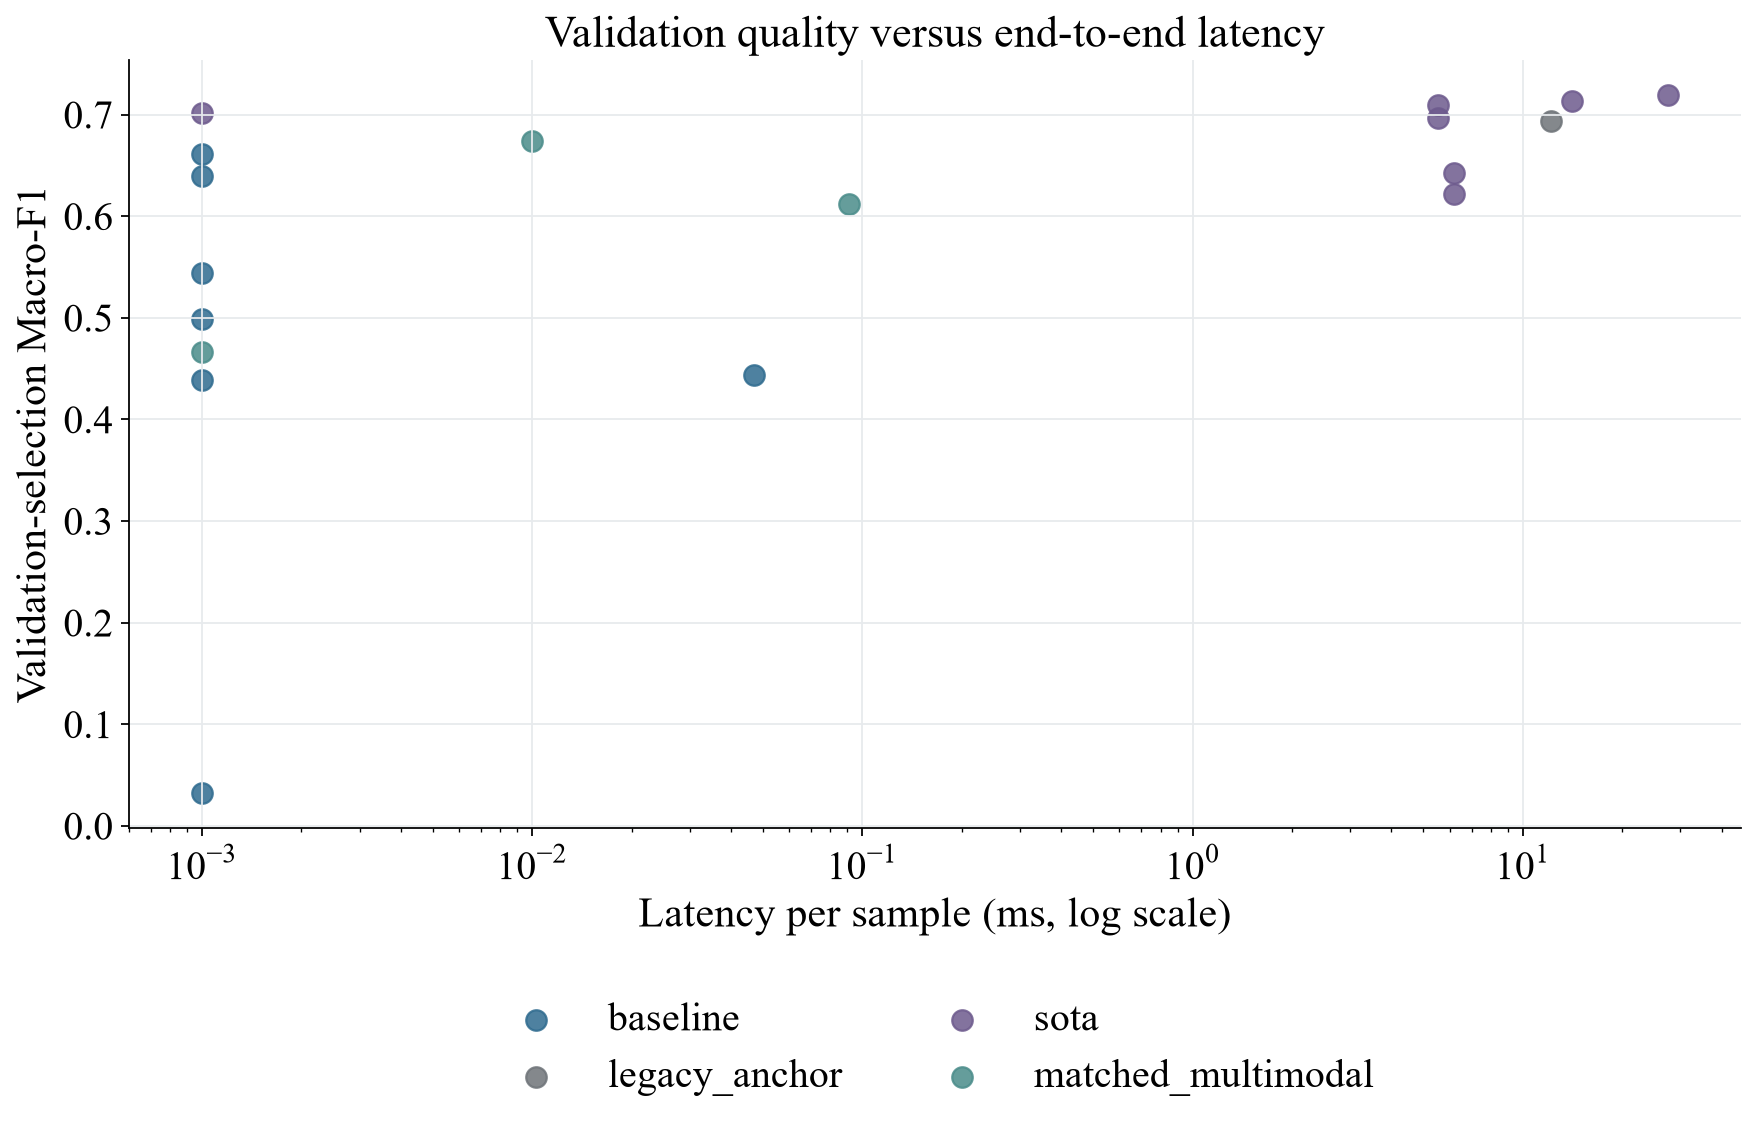

In [27]:
manifest = json.loads((DATASET / 'unified/semantic_embedding_manifest.json').read_text())
embedding_latency = {
    entry['model_id']: 1000 * entry['seconds'] / entry['rows'] for entry in manifest['models']
}
mapping = {
    'Legacy SPECTER + GPU linear': 'sentence-transformers/allenai-specter',
    'SPECTER2-base + GPU linear': 'allenai/specter2_base',
    'SPECTER2 classification adapter + GPU linear': 'allenai/specter2_base',
    'SciNCL + GPU linear': 'malteos/scincl',
    'Jina v5 nano + GPU linear': 'jinaai/jina-embeddings-v5-text-nano-classification',
    'Jina v5 nano + GPU MLP': 'jinaai/jina-embeddings-v5-text-nano-classification',
    'Qwen3-Embedding-0.6B instructed + GPU linear': 'Qwen/Qwen3-Embedding-0.6B',
}
efficiency_df = pd.DataFrame(efficiency_rows).drop_duplicates(['model', 'seed'])
efficiency_df['embedding_latency_ms_per_sample'] = efficiency_df.model.map(
    lambda name: embedding_latency.get(mapping.get(name, ''), 0)
)
efficiency_df['end_to_end_latency_ms_per_sample'] = (
    efficiency_df.cached_inference_ms_per_sample + efficiency_df.embedding_latency_ms_per_sample
)
efficiency_summary = efficiency_df.groupby('model', as_index=False).agg(
    training_seconds_mean=('training_seconds', 'mean'),
    cached_latency_ms_mean=('cached_inference_ms_per_sample', 'mean'),
    end_to_end_latency_ms_mean=('end_to_end_latency_ms_per_sample', 'mean'),
    trainable_parameters_mean=('trainable_parameters', 'mean'),
)
quality = summary[['model', 'macro_f1_mean']].merge(efficiency_summary, on='model', how='left')
fig, ax = plt.subplots(figsize=(13, 8))
for family, color in [
    ('baseline', PALETTE['blue']),
    ('legacy_anchor', PALETTE['gray']),
    ('sota', PALETTE['purple']),
    ('matched_multimodal', PALETTE['teal']),
]:
    names = set(summary.loc[summary.family.eq(family), 'model'])
    part = quality[quality.model.isin(names)]
    ax.scatter(
        part.end_to_end_latency_ms_mean.clip(lower=0.001),
        part.macro_f1_mean,
        s=85,
        color=color,
        label=family,
        alpha=0.85,
    )
ax.set_xscale('log')
ax.set_title('Validation quality versus end-to-end latency')
ax.set_xlabel('Latency per sample (ms, log scale)')
ax.set_ylabel('Validation-selection Macro-F1')
ax.grid(color=PALETTE['light_gray'])
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.28)
plt.show()

## Persist validation metrics and model configurations

In [28]:
metrics_df = pd.DataFrame(metric_rows)
classwise_df = pd.DataFrame(classwise_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
assert predictions_df.row_index.isin(sealed_idx).sum() == 0
metrics_df[metrics_df.family.isin(['baseline', 'legacy_anchor'])].to_csv(
    TABLES / 'baseline_metrics.csv', index=False
)
metrics_df[metrics_df.family.isin(['sota', 'matched_multimodal'])].to_csv(
    TABLES / 'sota_metrics.csv', index=False
)
predictions_df.to_parquet(TABLES / 'baseline_sota_predictions.parquet', index=False)
predictions_df.drop(columns=[c for c in predictions_df if c.startswith('probability_')]).to_csv(
    TABLES / 'baseline_sota_predictions.csv', index=False
)
classwise_df.to_csv(TABLES / 'baseline_sota_classwise_metrics.csv', index=False)
retrieval_df.to_csv(TABLES / 'retrieval_metrics.csv', index=False)
keyphrase_df.to_csv(TABLES / 'keyphrase_metrics.csv', index=False)
efficiency_df.to_csv(TABLES / 'efficiency_metrics.csv', index=False)
calibration_df.to_csv(TABLES / 'baseline_sota_calibration.csv', index=False)
rank = summary.sort_values('macro_f1_mean', ascending=False)


def strongest(families):
    return rank[rank.family.isin(families)].iloc[0].model


lock = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'selection_partition': 'validation_selection',
    'calibration_fit_partition': 'validation_calibration_fit',
    'calibration_eval_partition': 'validation_calibration_eval',
    'seeds': SEEDS,
    'strongest_baseline': strongest(['baseline']),
    'strongest_current_sota': strongest(['sota']),
    'strongest_matched_multimodal': strongest(['matched_multimodal']),
    'overall_validation_leader': rank.iloc[0].model,
    'temperature_model': best_model,
    'temperature_seed': best_seed,
    'temperature': temperature,
    'confirmatory_status': 'SEALED — no test/external predictions or metrics were computed in Notebook 03',
}
(ARTIFACTS / 'validation_selection_lock.json').write_text(
    json.dumps(lock, indent=2, ensure_ascii=False)
)
rank_display = (
    rank[
        [
            'model',
            'family',
            'track',
            'macro_f1_mean',
            'macro_f1_std',
            'seed_count',
            'balanced_accuracy_mean',
            'ece_mean',
        ]
    ]
    .head(12)
    .copy()
)
rank_display['macro_f1_sd'] = rank_display.apply(
    lambda row: 'N/A — one seed' if row.seed_count < 2 else f'{row.macro_f1_std:.6f}', axis=1
)
display(rank_display.drop(columns='macro_f1_std'))

,model,family,track,macro_f1_mean,seed_count,balanced_accuracy_mean,ece_mean,macro_f1_sd
10,Qwen3-Embedding-0.6B instructed + GPU linear,sota,primary_text,0.719295,3,0.724839,0.042518,0.000576
8,ModernBERT-base LoRA,sota,primary_text,0.713229,3,0.718995,0.076629,0.003374
11,SPECTER2 classification adapter + GPU linear,sota,primary_text,0.709918,3,0.715209,0.042973,0.000611
13,SciNCL + GPU linear,sota,primary_text,0.701871,3,0.709005,0.052362,0.001057
12,SPECTER2-base + GPU linear,sota,primary_text,0.696415,3,0.704163,0.032820,0.000720
6,Legacy SPECTER + GPU linear,legacy_anchor,primary_text,0.693880,3,0.701629,0.027024,0.000862
14,Static lexical–Jina late fusion,matched_multimodal,matched_four_modal,0.673978,3,0.679854,0.062196,0.000795
16,TF–IDF + GPU Logistic,baseline,primary_text,0.661174,3,0.667736,0.133817,0.000559
3,Jina v5 nano + GPU MLP,sota,primary_text,0.642857,3,0.646022,0.065773,0.007199
15,TF–IDF + GPU Linear SVM,baseline,primary_text,0.639442,3,0.639238,0.066638,0.001279
